# 02 — NBA Player Detection: Quantitative Evaluation

## Obiettivo

Questo notebook valuta quantitativamente il modello **RF-DETR** utilizzato nella pipeline di Computer Vision sviluppata per la tesi magistrale *Automatic Player Tracking & Tactical Analysis in Basketball*.

La valutazione utilizza il dataset **Basketball Player Detection v18**, disponibile su Roboflow Universe e annotato nel formato COCO JSON.

L'obiettivo principale è misurare le prestazioni del detector nella classe `player`, confrontando le bounding box predette con le annotazioni di riferimento.

## Pipeline sperimentale

Dataset COCO → Pretrained RF-DETR → Object Detection → Matching delle bounding box → Precision, Recall e Average Precision.

## Metodologia

- Utilizzo del checkpoint già impiegato nel Notebook 1, senza ulteriore addestramento.
- Analisi delle immagini del test set.
- Verifica della compatibilità delle classi e del possibile riutilizzo di immagini viste durante il training.
- Valutazione quantitativa mediante metriche standard di Object Detection.
- Analisi qualitativa degli errori di rilevamento.

## Output previsti

- Tabelle delle metriche di detection.
- Predizioni e annotazioni confrontabili.
- Visualizzazioni dei principali errori.
- Risultati sperimentali utilizzabili nella tesi.

**Nota:** il dataset di Object Detection non contiene necessariamente annotazioni di identità temporale e non permette, da solo, di valutare SAM2 tramite metriche di Multiple Object Tracking.

In [1]:
import sys
import torch

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("GPU disponibile:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    raise RuntimeError(
        "Attiva una GPU dalle impostazioni del runtime, "
        "poi esegui nuovamente questa cella."
    )

Python: 3.13.15
PyTorch: 2.11.0+cu130
GPU disponibile: True
GPU: Tesla T4


In [2]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
%pip install -q inference-gpu

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.7/105.7 kB 8.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.6/68.6 kB 5.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 6.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 47.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.4/99.4 kB 11.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.8/46.8 kB 5.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 4.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10

In [1]:
import PIL
from PIL import Image, ImageFont, ImageText

print("Pillow:", PIL.__version__)
print("Import delle librerie immagini riuscito.")

Pillow: 12.3.0
Import delle librerie immagini riuscito.


In [2]:
from inference import get_model

print("Inference importato correttamente!")

/usr/local/lib/python3.13/dist-packages/inference/core/env.py:345: InferenceDeprecationWarning: CORE_MODEL_GAZE_ENABLED is True: POST /gaze/gaze_detection is registered as a deprecation stub returning HTTP 410 Gone. The stub and this flag will be removed end of Q2 2026. Set CORE_MODEL_GAZE_ENABLED=False to disable it now.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
[transformers] `DepthProImageProcessorFast` is deprecated. The `Fast` suffix for image processors has been removed; use `DepthProImageProcessor` instead.


Inference importato correttamente!


/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/inference/models/utils.py:775: ModelDependencyMissing: Your `inference` configuration does not support YoloWorld model. Use pip install 'inference[yolo-world]' to install missing requirements.To suppress this warning, set CORE_MODEL_YOLO_WORLD_ENABLED to False.
  warnings.warn(


In [3]:
from PIL import Image, ImageDraw, ImageFont
from inference import get_model

print("Pillow e inference importati correttamente.")

Pillow e inference importati correttamente.


In [4]:
import os
from getpass import getpass
from inference import get_model

# Richiedila nuovamente, anche se esiste già in memoria.
api_key = getpass("API key privata Roboflow: ").strip()

if not api_key:
    raise ValueError("Chiave non inserita.")

os.environ["ROBOFLOW_API_KEY"] = api_key

PLAYER_MODEL_ID = "basketball-player-detection-3-ycjdo/4"

# Impedisci di riutilizzare un vecchio oggetto dopo un caricamento fallito.
player_model = None

try:
    player_model = get_model(
        model_id=PLAYER_MODEL_ID,
        api_key=api_key,
    )
    print("Modello caricato:", PLAYER_MODEL_ID)
    print("Architettura:", type(player_model).__name__)
except Exception as error:
    print("Caricamento fallito:", type(error).__name__)
    print("Il modello non è disponibile per la valutazione.")
finally:
    del api_key

API key privata Roboflow: ··········


Output()

Modello caricato: basketball-player-detection-3-ycjdo/4
Architettura: InferenceModelsObjectDetectionAdapter


4 — Backup immediato del runtime funzionante

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
ROOT = Path('/content/drive/MyDrive/NBA_Tracking_Project')
ROOT.mkdir(parents=True, exist_ok=True)
print('Import riusciti.')


In [5]:
import os, json, shutil, hashlib, sys, subprocess
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version, PackageNotFoundError
assert globals().get('player_model') is not None, 'Carica prima il modello.'
ROOT = Path('/content/drive/MyDrive/NBA_Tracking_Project')
assert Path('/content/drive/MyDrive').exists(), 'Monta prima Drive.'
cache = Path(os.environ.get('INFERENCE_HOME') or os.environ.get('MODEL_CACHE_DIR') or '/tmp/cache').expanduser()
assert cache.is_dir(), 'Cache non trovata: non considerare il modello salvato.'
files = [p for p in cache.rglob('*') if p.is_file()]
assert files, 'Cache vuota.'
BACKUP = ROOT / 'models' / ('player_model_v4_backup_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ'))
BACKUP.mkdir(parents=True, exist_ok=False)
shutil.copytree(cache, BACKUP / 'cache', symlinks=False)
records = []
for p in (BACKUP / 'cache').rglob('*'):
    if p.is_file():
        h = hashlib.sha256()
        with p.open('rb') as f:
            for block in iter(lambda: f.read(1024*1024), b''):
                h.update(block)
        records.append({'path': str(p.relative_to(BACKUP)), 'bytes': p.stat().st_size, 'sha256': h.hexdigest()})
packages = {}
for name in ['inference-gpu','inference','inference-models','supervision','Pillow','torch','numpy','pycocotools']:
    try: packages[name] = version(name)
    except PackageNotFoundError: pass
manifest = {'model_id': 'basketball-player-detection-3-ycjdo/4', 'adapter': type(player_model).__name__, 'python': sys.version, 'packages': packages, 'files': records, 'restore_verified': False}
(BACKUP / 'manifest.json').write_text(json.dumps(manifest, indent=2))
freeze = subprocess.run([sys.executable, '-m', 'pip', 'freeze'], capture_output=True, text=True, check=True).stdout
# Freeze conservato solo per pacchetti con versioni, evitando URL di installazione.
(BACKUP / 'requirements_snapshot.txt').write_text('\n'.join(line for line in freeze.splitlines() if '==' in line and ' @ ' not in line and '://' not in line))
print('Backup scritto:', BACKUP)
print('File copiati:', len(records))
print('MB copiati:', round(sum(r['bytes'] for r in records)/1e6, 2))
print('Ripristino ancora da verificare.')


Backup scritto: /content/drive/MyDrive/NBA_Tracking_Project/models/player_model_v4_backup_20261011T093526Z
File copiati: 19
MB copiati: 75.6
Ripristino ancora da verificare.


5 — Annotazioni di test

In [6]:
from pathlib import Path

project = Path("/content/drive/MyDrive/NBA_Tracking_Project")

coco_files = sorted(project.rglob("*coco*.json"))

if coco_files:
    for path in coco_files:
        print(path)
else:
    print("Nessun file COCO trovato nella cartella del progetto.")

/content/drive/MyDrive/NBA_Tracking_Project/datasets/basketball_player_detection_v18/test/_annotations.coco.json
/content/drive/MyDrive/NBA_Tracking_Project/outputs/detection_evaluation/rfdetr_small_coco_predictions.json


In [7]:
from pathlib import Path
from pycocotools.coco import COCO

TEST_IMAGES = Path(
    "/content/drive/MyDrive/NBA_Tracking_Project/"
    "datasets/basketball_player_detection_v18/test"
)

COCO_JSON = TEST_IMAGES / "_annotations.coco.json"
INDEPENDENCE_VERIFIED = False

assert COCO_JSON.is_file(), f"Annotazioni mancanti: {COCO_JSON}"

coco_original = COCO(str(COCO_JSON))

print("\nClassi presenti:")
for cat in coco_original.dataset["categories"]:
    print(cat["id"], cat["name"])

print("\nImmagini di test:", len(coco_original.getImgIds()))

missing = [
    img["file_name"]
    for img in coco_original.dataset["images"]
    if not (TEST_IMAGES / img["file_name"]).is_file()
]

print("Immagini mancanti:", len(missing))
if missing:
    print("Primi file mancanti:", missing[:5])

loading annotations into memory...
Done (t=0.34s)
creating index...
index created!

Classi presenti:
0 basketball
1 ball
2 ball-in-basket
3 number
4 player
5 player-in-possession
6 player-jump-shot
7 player-layup-dunk
8 player-shot-block
9 referee
10 rim

Immagini di test: 94
Immagini mancanti: 0


### 6 — Definisci cosa conta come giocatore
Compila le due liste dopo aver letto le classi. Per valutare tutti i giocatori, includi anche eventuali classi di azione (possesso, tiro ecc.) nelle annotazioni e nelle predizioni. Non includere arbitri o numeri di maglia.
Il codice richiede una lista esplicita per evitare una valutazione involontariamente parziale.

In [8]:
GT_PLAYER_CLASSES = {'player', 'player-in-possession','player-jump-shot','player-layup-dunk','player-shot-block'}  # Adatta ai nomi STAMPATI nella cella 5.
PRED_PLAYER_CLASSES = GT_PLAYER_CLASSES.copy()  # Adatta anche alle altre classi di giocatore del modello.
known = {c['name'] for c in coco_original.dataset['categories']}
assert GT_PLAYER_CLASSES <= known, f'Classi inesistenti: {GT_PLAYER_CLASSES-known}'
print('Possibili classi di giocatore non incluse:', sorted(n for n in known-GT_PLAYER_CLASSES if 'player' in n.lower()))
# Controllo di una predizione reale; non deduciamo i nomi dalle classi GT.
import cv2
im0 = coco_original.loadImgs(coco_original.getImgIds()[0])[0]
frame0 = cv2.imread(str(TEST_IMAGES / im0['file_name']))
assert frame0 is not None, 'Percorso immagini non corretto.'
result0 = player_model.infer(frame0, confidence=0.001, iou_threshold=0.9)[0]
print('Classi predette sulla prima immagine:', sorted({p.class_name for p in result0.predictions}))
print('Prima di proseguire, verifica le liste: una sola immagine non mostra necessariamente tutte le classi.')


Possibili classi di giocatore non incluse: []
Classi predette sulla prima immagine: ['ball', 'ball-in-basket', 'number', 'player', 'referee', 'rim']
Prima di proseguire, verifica le liste: una sola immagine non mostra necessariamente tutte le classi.


7 — Crea ground truth unificata

In [9]:
import copy
from datetime import datetime, timezone
OUT = ROOT / 'outputs' / ('detection_eval_v4_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ'))
OUT.mkdir(parents=True, exist_ok=False)
ids = {c['id'] for c in coco_original.dataset['categories'] if c['name'] in GT_PLAYER_CLASSES}
data = copy.deepcopy(coco_original.dataset)
data['categories'] = [{'id': 1, 'name': 'player'}]
data['info'] = data.get('info', {})
data['annotations'] = [a for a in data['annotations'] if a['category_id'] in ids]
assert data['annotations'], 'Nessuna annotazione giocatore.'
for a in data['annotations']:
    a['category_id'] = 1
    a.setdefault('iscrowd', 0)
    a.setdefault('area', a['bbox'][2]*a['bbox'][3])
(OUT / 'ground_truth_players.json').write_text(json.dumps(data))
coco_gt = COCO(str(OUT / 'ground_truth_players.json'))


loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


8 — Predizioni su tutte le immagini

In [10]:
import numpy as np
from tqdm.auto import tqdm
CONF_FOR_AP = 0.001
NMS_IOU = 0.7
def nms(rows):
    kept=[]
    for row in sorted(rows, key=lambda r: r['score'], reverse=True):
        x,y,w,h = row['bbox']
        reject=False
        for other in kept:
            xx,yy,ww,hh = other['bbox']
            inter=max(0,min(x+w,xx+ww)-max(x,xx))*max(0,min(y+h,yy+hh)-max(y,yy))
            if inter/max(w*h+ww*hh-inter,1e-9)>NMS_IOU:
                reject=True; break
        if not reject: kept.append(row)
    return kept
predictions=[]
for image_id in tqdm(sorted(coco_gt.getImgIds())):
    info=coco_gt.loadImgs(image_id)[0]
    frame=cv2.imread(str(TEST_IMAGES / info['file_name']))
    assert frame is not None, f"Immagine illeggibile: {info['file_name']}"
    assert (frame.shape[1],frame.shape[0])==(info['width'],info['height']), 'Dimensioni COCO diverse dalle immagini.'
    result=player_model.infer(frame, confidence=CONF_FOR_AP, iou_threshold=0.9)[0]
    rows=[]
    for p in result.predictions:
        if p.class_name not in PRED_PLAYER_CLASSES: continue
        x1=max(0.,float(p.x-p.width/2)); y1=max(0.,float(p.y-p.height/2))
        x2=min(float(info['width']),float(p.x+p.width/2)); y2=min(float(info['height']),float(p.y+p.height/2))
        if x2>x1 and y2>y1:
            rows.append({'image_id':image_id,'category_id':1,'bbox':[x1,y1,x2-x1,y2-y1],'score':float(p.confidence)})
    predictions.extend(nms(rows))
(OUT / 'predictions.json').write_text(json.dumps(predictions))
print('Predizioni salvate:', len(predictions))


  0%|          | 0/94 [00:00<?, ?it/s]

Predizioni salvate: 1843


9 — AP COCO e precision/recall alla soglia operativa

In [11]:
from pycocotools.cocoeval import COCOeval
if predictions:
    coco_dt = coco_gt.loadRes(predictions)
else:
    coco_dt=COCO(); coco_dt.dataset={'images':data['images'],'categories':data['categories'],'annotations':[]}; coco_dt.createIndex()
evaluator=COCOeval(coco_gt,coco_dt,'bbox')
evaluator.params.imgIds=sorted(coco_gt.getImgIds())
evaluator.params.catIds=[1]
evaluator.evaluate(); evaluator.accumulate(); evaluator.summarize()
operating_conf=0.4
op=COCOeval(coco_gt,coco_dt,'bbox')
op.params.imgIds=evaluator.params.imgIds
op.params.catIds=[1]; op.params.iouThrs=np.array([0.5]); op.params.areaRng=[[0,1e10]]; op.params.areaRngLbl=['all']; op.params.maxDets=[100]
op.evaluate()
tp=fp=fn=0
for e in op.evalImgs:
    if e is None: continue
    selected=np.asarray(e['dtScores'])>=operating_conf
    valid=selected & ~np.asarray(e['dtIgnore'][0],dtype=bool)
    tp+=int(np.sum(valid & (e['dtMatches'][0]>0)))
    fp+=int(np.sum(valid & (e['dtMatches'][0]==0)))
    matched=set(e['dtMatches'][0][valid])- {0}
    fn+=sum(not ignore and gid not in matched for gid,ignore in zip(e['gtIds'],e['gtIgnore']))
precision=tp/(tp+fp) if tp+fp else 0.
recall=tp/(tp+fn) if tp+fn else 0.
metrics={'model_id':PLAYER_MODEL_ID,'n_images':len(data['images']),'AP50_95':float(evaluator.stats[0]),'AP50':float(evaluator.stats[1]),'precision_conf04_iou05':precision,'recall_conf04_iou05':recall,'TP':tp,'FP':fp,'FN':fn,'independence_verified':INDEPENDENCE_VERIFIED,'gt_classes':sorted(GT_PLAYER_CLASSES),'pred_classes':sorted(PRED_PLAYER_CLASSES),'conf_for_ap':CONF_FOR_AP,'nms_iou':NMS_IOU,'annotation_sha256':hashlib.sha256(COCO_JSON.read_bytes()).hexdigest()}
(OUT / 'metrics.json').write_text(json.dumps(metrics,indent=2))
print(json.dumps(metrics,indent=2))
print('Output:',OUT)
if not INDEPENDENCE_VERIFIED: print('RISULTATI PRELIMINARI: indipendenza dal training non verificata.')


Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.36s).
Accumulating evaluation results...
DONE (t=0.03s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.846
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.987
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.923
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.847
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.097
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.865
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.875
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=1

---
## 10 — Analisi IoU delle bounding box (categoria unificata)

Questa sezione riutilizza `coco_gt`, `coco_dt`, `predictions` e `OUT` generati dalle celle precedenti, senza richiamare il modello. Calcola l'IoU delle coppie TP secondo il matching COCO alla soglia **IoU ≥ 0,50** e **confidence ≥ 0,40**. La media è **condizionata ai veri positivi**: non sostituisce la mAP e non include FN/FP.

Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.09s).
True Positive con IoU misurata: 927
Mean IoU (solo TP): 0.9141
Median IoU (solo TP): 0.9405
Deviazione standard: 0.0794
Percentili IoU (10/25/75/90): {0.1: 0.8141, 0.25: 0.8943, 0.75: 0.9643, 0.9: 0.9771}


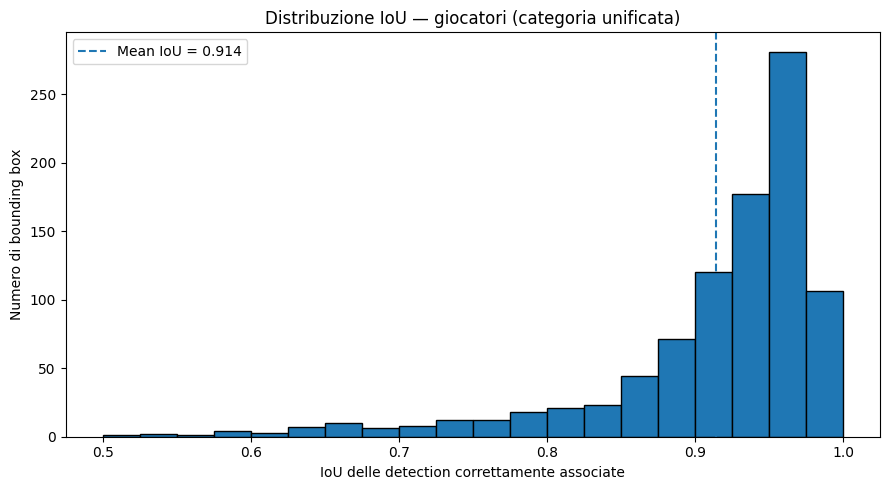


Distribuzione per intervalli:
iou
[0.5, 0.6)      8
[0.6, 0.7)     26
[0.7, 0.8)     50
[0.8, 0.9)    159
[0.9, 1.0)    684


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pycocotools.cocoeval import COCOeval

IOU_MATCH = 0.50
CONF_OPERATING = 0.40

# COCOeval assegna ogni detection a una sola GT (se possibile).
match_eval = COCOeval(coco_gt, coco_dt, 'bbox')
match_eval.params.imgIds = sorted(coco_gt.getImgIds())
match_eval.params.catIds = [1]
match_eval.params.iouThrs = np.array([IOU_MATCH])
match_eval.params.areaRng = [[0, 1e10]]
match_eval.params.areaRngLbl = ['all']
match_eval.params.maxDets = [100]
match_eval.evaluate()

rows = []
for e in match_eval.evalImgs:
    if e is None:
        continue
    # Le IoU effettive vengono ricomputate dalle bbox originali delle coppie assegnate.
    img_id = int(e['image_id'])
    for k, (det_id, score) in enumerate(zip(e['dtIds'], e['dtScores'])):
        if score < CONF_OPERATING or bool(e['dtIgnore'][0, k]):
            continue
        gt_id = int(e['dtMatches'][0, k])
        if gt_id <= 0:
            continue
        det = coco_dt.anns[int(det_id)]
        gt = coco_gt.anns[gt_id]
        x1,y1,w1,h1 = map(float,det['bbox'])
        x2,y2,w2,h2 = map(float,gt['bbox'])
        ix = max(0., min(x1+w1,x2+w2)-max(x1,x2))
        iy = max(0., min(y1+h1,y2+h2)-max(y1,y2))
        inter = ix*iy
        union = w1*h1+w2*h2-inter
        val = inter/union if union > 0 else 0.
        rows.append({'image_id':img_id,'prediction_id':int(det_id),
                     'gt_id':gt_id,'confidence':float(score),'iou':val})

iou_df = pd.DataFrame(rows,columns=['image_id','prediction_id','gt_id','confidence','iou'])
assert not iou_df.empty, 'Nessun true positive alle soglie specificate.'
iou_df.to_csv(OUT/'matched_iou_unified.csv',index=False)
print('True Positive con IoU misurata:',len(iou_df))
print('Mean IoU (solo TP):',round(iou_df.iou.mean(),4))
print('Median IoU (solo TP):',round(iou_df.iou.median(),4))
print('Deviazione standard:',round(iou_df.iou.std(),4))
print('Percentili IoU (10/25/75/90):',iou_df.iou.quantile([.10,.25,.75,.90]).round(4).to_dict())

fig,ax=plt.subplots(figsize=(9,5))
ax.hist(iou_df.iou,bins=np.linspace(.5,1.,21),edgecolor='black')
ax.axvline(iou_df.iou.mean(),linestyle='--',label=f'Mean IoU = {iou_df.iou.mean():.3f}')
ax.set(xlabel='IoU delle detection correttamente associate',ylabel='Numero di bounding box',title='Distribuzione IoU — giocatori (categoria unificata)')
ax.legend();fig.tight_layout()
fig.savefig(OUT/'iou_distribution_unified.png',dpi=180)
plt.show()

bins = pd.cut(
    iou_df.iou,
    bins=[.5, .6, .7, .8, .9, 1.000001],
    right=False,
    include_lowest=True
)

print('\nDistribuzione per intervalli:')
print(bins.value_counts().sort_index().to_string())

## 11 — Metriche **per classe originale**

La valutazione precedente unifica tutte le tipologie di giocatore. Questa cella esegue una **seconda inferenza** con lo stesso modello sullo stesso test set, ma preserva i nomi delle classi. Riutilizza l'`OUT` della run corrente e salva i risultati nella sottocartella `per_class/`. Unisce le annotazioni originali COCO senza modificarle. Le metriche dipendono dalle annotazioni e potrebbero essere instabili per classi rare. Una classe senza esempi GT avrà metriche non disponibili.

In [17]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
from tqdm.auto import tqdm
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

CLASS_DIR = OUT / 'per_class'
CLASS_DIR.mkdir(parents=True,exist_ok=True)
all_class_names = sorted(GT_PLAYER_CLASSES)
original_ids = {c['name']:int(c['id']) for c in coco_original.dataset['categories']}
assert all(name in original_ids for name in all_class_names)
class_names_to_eval = {k:original_ids[k] for k in all_class_names}

# Mantieni solo le classi di giocatore; classi originali e bbox NON vengono fuse.
import copy
native_data = copy.deepcopy(coco_original.dataset)
native_data['categories'] = [c for c in native_data['categories'] if c['name'] in class_names_to_eval]
native_data['annotations'] = [a for a in native_data['annotations'] if a['category_id'] in set(class_names_to_eval.values())]
for a in native_data['annotations']:
    a.setdefault('iscrowd',0)
    a.setdefault('area',a['bbox'][2]*a['bbox'][3])
native_path=CLASS_DIR/'ground_truth_by_class.json'
native_path.write_text(json.dumps(native_data),encoding='utf-8')
native_gt=COCO(str(native_path))

# Non chiamare due volte il modello se il JSON è già stato salvato per questa stessa run.
native_pred_path=CLASS_DIR/'predictions_by_class.json'
if native_pred_path.exists():
    native_preds=json.loads(native_pred_path.read_text(encoding='utf-8'))
    print('Riutilizzo delle predizioni per classe già salvate.')
else:
    native_preds=[]
    for image_id in tqdm(sorted(native_gt.getImgIds()),desc='Predizioni per classe'):
        info=native_gt.loadImgs(image_id)[0]
        frame=cv2.imread(str(TEST_IMAGES/info['file_name']))
        assert frame is not None,f'Immagine illeggibile: {info["file_name"]}'
        result=player_model.infer(frame,confidence=CONF_FOR_AP,iou_threshold=0.9)[0]
        per_image=[]
        for det in result.predictions:
            if det.class_name not in class_names_to_eval: continue
            x1=max(0.,float(det.x-det.width/2)); y1=max(0.,float(det.y-det.height/2))
            x2=min(float(info['width']),float(det.x+det.width/2))
            y2=min(float(info['height']),float(det.y+det.height/2))
            if x2>x1 and y2>y1:
                per_image.append({'image_id':int(image_id),
                    'category_id':class_names_to_eval[det.class_name],
                    'bbox':[x1,y1,x2-x1,y2-y1],
                    'score':float(det.confidence)})
        # NMS SOLO tra bbox della stessa classe (non si eliminano classi diverse).
        for cat_id in set(row['category_id'] for row in per_image):
            native_preds.extend(nms([row for row in per_image if row['category_id']==cat_id]))
    native_pred_path.write_text(json.dumps(native_preds),encoding='utf-8')

if native_preds:
    native_dt=native_gt.loadRes(native_preds)
else:
    native_dt=COCO()
    native_dt.dataset={'images':native_data['images'],'categories':native_data['categories'],
                       'annotations':[],'info':native_data.get('info',{})}
    native_dt.createIndex()

class_rows=[]
for class_name,cat_id in class_names_to_eval.items():
    gt_count=sum(a['category_id']==cat_id for a in native_data['annotations'])
    c_eval=COCOeval(native_gt,native_dt,'bbox')
    c_eval.params.imgIds=sorted(native_gt.getImgIds())
    c_eval.params.catIds=[cat_id]
    c_eval.evaluate()
    c_eval.accumulate()
    c_eval.summarize()

    ap5095 = float(c_eval.stats[0])
    ap50 = float(c_eval.stats[1])
    # stats non viene valorizzato da accumulate(): usiamo il tensore precision [T,R,K,A,M].
    prec=c_eval.eval['precision'][:,:,:,0,2]
    def coco_ap(iou_index):
        z=prec[iou_index,:,:]
        good=z[z>=0]
        return float(good.mean()) if good.size else np.nan
    ap50=coco_ap(0)
    valid=prec[prec>=0]
    ap5095=float(valid.mean()) if valid.size else np.nan

    op_c=COCOeval(native_gt,native_dt,'bbox')
    op_c.params.imgIds=sorted(native_gt.getImgIds())
    op_c.params.catIds=[cat_id]
    op_c.params.iouThrs=np.array([0.5])
    op_c.params.areaRng=[[0,1e10]]
    op_c.params.areaRngLbl=['all']
    op_c.params.maxDets=[100]
    op_c.evaluate()
    tp_c=fp_c=fn_c=0
    for e in op_c.evalImgs:
        if e is None: continue
        selected=np.asarray(e['dtScores'])>=CONF_OPERATING
        valid_d=selected & ~np.asarray(e['dtIgnore'][0],dtype=bool)
        tp_c+=int(np.sum(valid_d&(e['dtMatches'][0]>0)))
        fp_c+=int(np.sum(valid_d&(e['dtMatches'][0]==0)))
        matched=set(e['dtMatches'][0][valid_d])-{0}
        fn_c+=sum(not ignore and gid not in matched for gid,ignore in zip(e['gtIds'],e['gtIgnore']))
    p=tp_c/(tp_c+fp_c) if tp_c+fp_c else np.nan
    r=tp_c/(tp_c+fn_c) if tp_c+fn_c else np.nan
    f1=2*p*r/(p+r) if np.isfinite(p) and np.isfinite(r) and p+r else np.nan
    class_rows.append({'classe':class_name,'gt_count':gt_count,'TP':tp_c,'FP':fp_c,'FN':fn_c,
        'precision':p,'recall':r,'F1':f1,'AP50':ap50,'AP50_95':ap5095})

class_df=pd.DataFrame(class_rows)
class_df.to_csv(CLASS_DIR/'metrics_per_class.csv',index=False)
print(class_df.round(4).to_string(index=False))
print('File salvato:',CLASS_DIR/'metrics_per_class.csv')

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Riutilizzo delle predizioni per classe già salvate.
Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.31s).
Accumulating evaluation results...
DONE (t=0.02s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.838
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.974
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.911
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.839
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.101
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.869
 Average Re

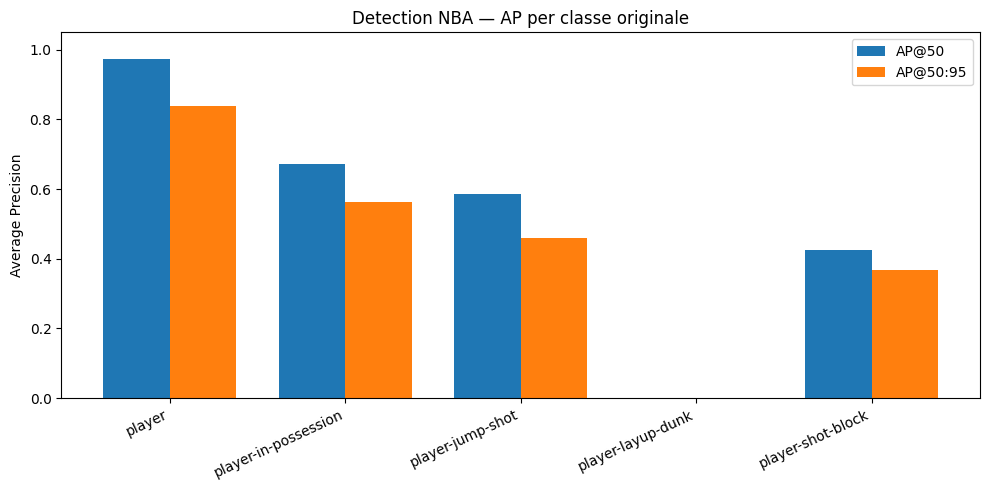

Tutti gli output sono in: /content/drive/MyDrive/NBA_Tracking_Project/outputs/detection_eval_v4_20261011T093539Z


In [18]:
# Grafico AP e tabella di riepilogo riproducibile
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(10,5))
x=np.arange(len(class_df)); w=.38
ax.bar(x-w/2,class_df['AP50'],width=w,label='AP@50')
ax.bar(x+w/2,class_df['AP50_95'],width=w,label='AP@50:95')
ax.set_xticks(x,class_df['classe'],rotation=25,ha='right')
ax.set_ylim(0,1.05); ax.set_ylabel('Average Precision')
ax.set_title('Detection NBA — AP per classe originale');ax.legend()
fig.tight_layout();fig.savefig(CLASS_DIR/'ap_per_class.png',dpi=180);plt.show()

summary={'model_id':PLAYER_MODEL_ID,'n_images':len(native_data['images']),
    'mean_iou_matched_tp':float(iou_df.iou.mean()),
    'median_iou_matched_tp':float(iou_df.iou.median()),
    'matched_tp_count':int(len(iou_df)),
    'iou_matching_threshold':IOU_MATCH,'confidence_threshold':CONF_OPERATING,
    'independence_verified':bool(INDEPENDENCE_VERIFIED),
    'important_note':'mean IoU on matched TP only; not dataset mean IoU and not mAP'}
(OUT/'extended_metrics_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
print('Tutti gli output sono in:',OUT)